In [41]:
# Importing the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# Evaluation metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [42]:
#Analyzing the data
df = pd.read_csv('Solar Power Plant Data.csv')
print(df.head())
print(df.shape)
print(df.info())
print(df.describe())

     Date-Hour(NMT)  WindSpeed  Sunshine  AirPressure  Radiation  \
0  01.01.2017-00:00        0.6         0       1003.8       -7.4   
1  01.01.2017-01:00        1.7         0       1003.5       -7.4   
2  01.01.2017-02:00        0.6         0       1003.4       -6.7   
3  01.01.2017-03:00        2.4         0       1003.3       -7.2   
4  01.01.2017-04:00        4.0         0       1003.1       -6.3   

   AirTemperature  RelativeAirHumidity  SystemProduction  
0             0.1                   97               0.0  
1            -0.2                   98               0.0  
2            -1.2                   99               0.0  
3            -1.3                   99               0.0  
4             3.6                   67               0.0  
(8760, 8)
<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date-Hour(NMT)       8760 n

In [43]:
#Checking for missing values
print(df.isnull().sum())

Date-Hour(NMT)         0
WindSpeed              0
Sunshine               0
AirPressure            0
Radiation              0
AirTemperature         0
RelativeAirHumidity    0
SystemProduction       0
dtype: int64


In [44]:
#Checking for duplicate values
print(df.duplicated().sum())

0


In [45]:
#Converting the 'Date-Hour(NMT)' column to datetime format
df['Date-Hour(NMT)'] = pd.to_datetime(
    df['Date-Hour(NMT)'],
    format='%d.%m.%Y-%H:%M'
)

print(df['Date-Hour(NMT)'].head(10))

0   2017-01-01 00:00:00
1   2017-01-01 01:00:00
2   2017-01-01 02:00:00
3   2017-01-01 03:00:00
4   2017-01-01 04:00:00
5   2017-01-01 05:00:00
6   2017-01-01 06:00:00
7   2017-01-01 07:00:00
8   2017-01-01 08:00:00
9   2017-01-01 09:00:00
Name: Date-Hour(NMT), dtype: datetime64[us]


In [46]:
#Selecting the features and target variable
X = df[['Radiation', 'Sunshine',
        'AirTemperature', 'WindSpeed',
        'AirPressure', 'RelativeAirHumidity']]

y = df['SystemProduction']

In [47]:
#Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, shuffle=True
)

In [48]:
#Scaling the input features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

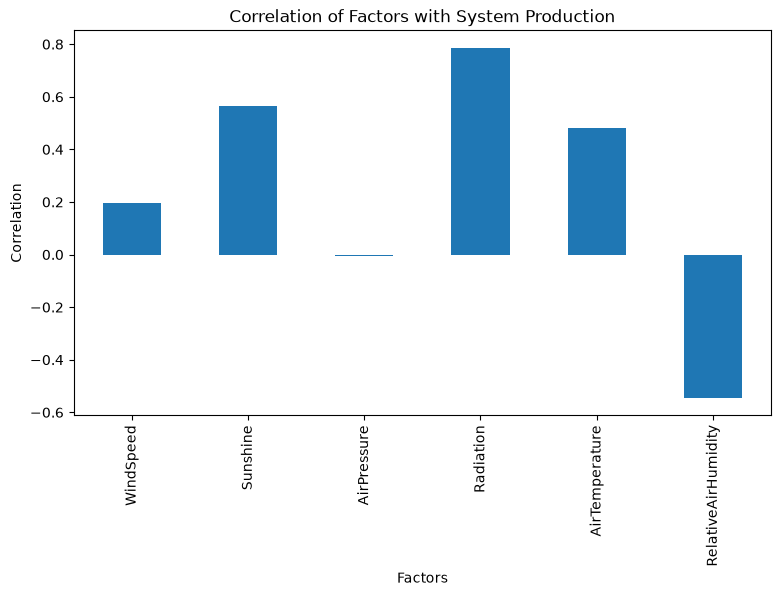

In [49]:
# Graph 1 : Correlation of Factors with System Production

correlation_with_production = df.corr(numeric_only = True)['SystemProduction'] 
correlation_with_production = correlation_with_production.drop('SystemProduction')

plt.figure(figsize = (9,5))
correlation_with_production.plot.bar()
plt.title('Correlation of Factors with System Production')
plt.xlabel('Factors')
plt.ylabel('Correlation')
plt.show()

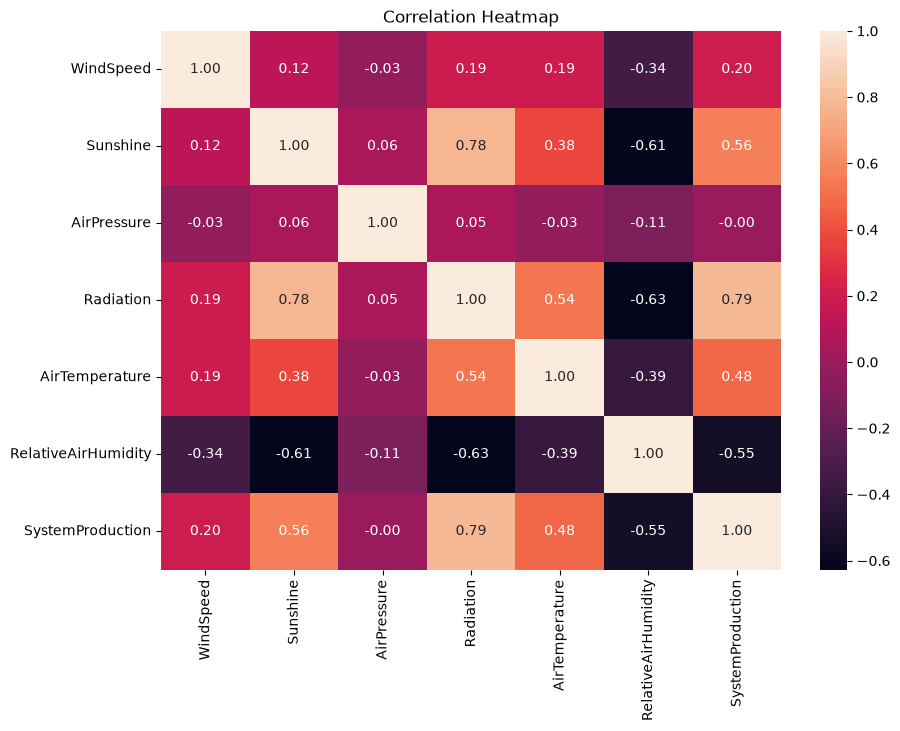

In [50]:
# Graph 2 : Correlation Heatmap

plt.figure(figsize = (10, 7))

correlation = df.corr(numeric_only = True)

sns.heatmap(correlation, annot = True, fmt = '.2f')
plt.title('Correlation Heatmap')
plt.show()

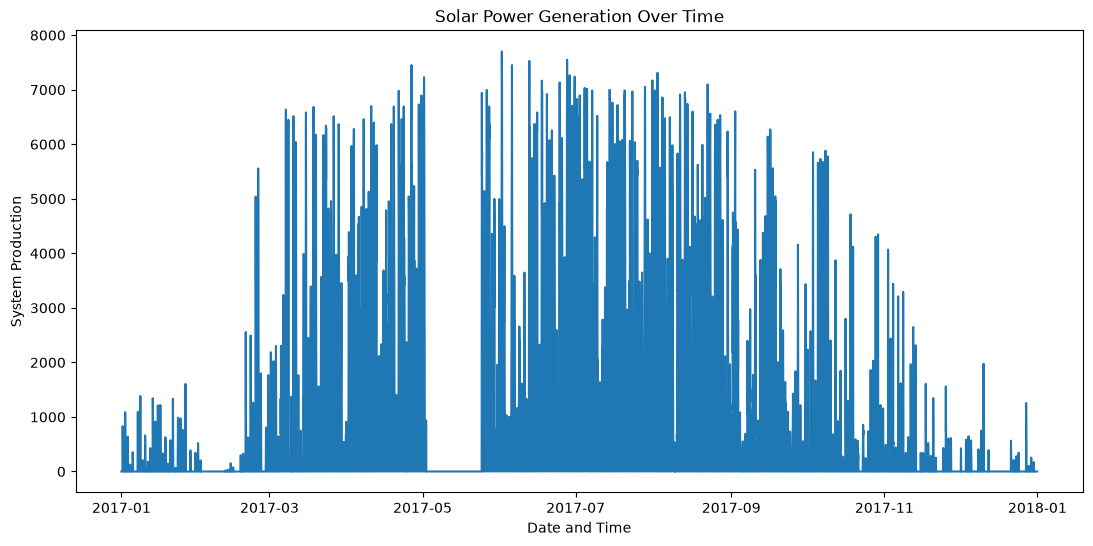

In [51]:
# Graph 1 : Solar Power Generation Over Time

plt.figure(figsize=(13, 6))
plt.plot(
    df['Date-Hour(NMT)'],
    df['SystemProduction']
)
plt.title('Solar Power Generation Over Time')
plt.xlabel('Date and Time')
plt.ylabel('System Production')
plt.show()


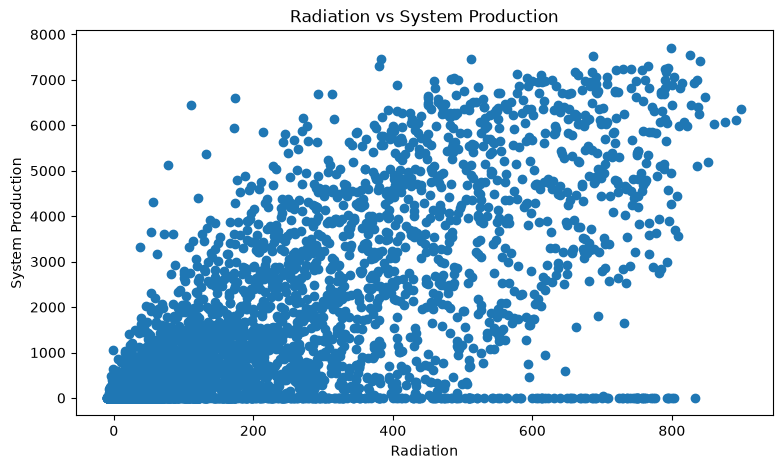

In [52]:
# Graph 2 : Radiation vs System Production

plt.figure(figsize = (9,5))
plt.scatter(
    df['Radiation'],
    df['SystemProduction']
)
plt.title('Radiation vs System Production')
plt.xlabel('Radiation')
plt.ylabel('System Production')
plt.show()

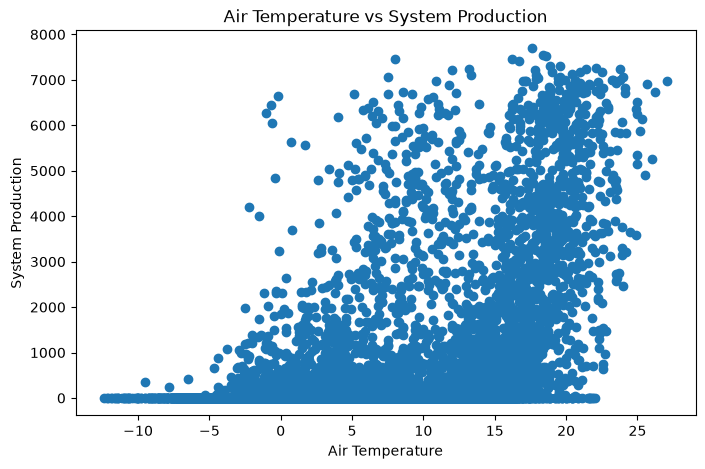

In [53]:
# Graph 3 : Air Temperature vs System Production

plt.figure(figsize = (8,5))
plt.scatter(
    df['AirTemperature'],
    df['SystemProduction']
)
plt.title('Air Temperature vs System Production')
plt.xlabel('Air Temperature')
plt.ylabel('System Production')
plt.show()

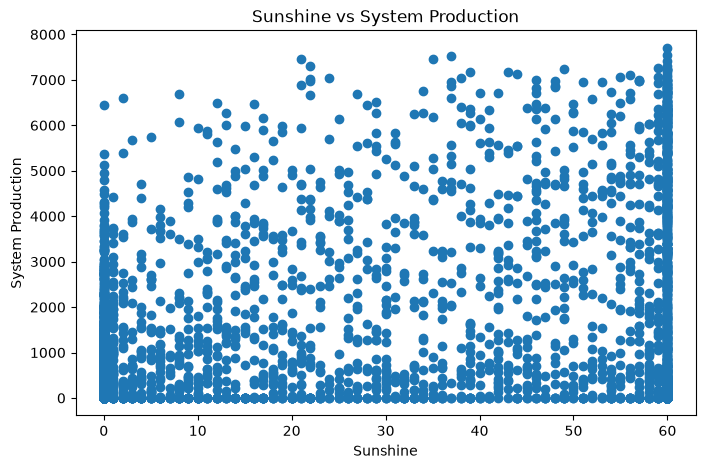

In [54]:
# Graph 4 : Sunshine vs System Production

plt.figure(figsize = (8,5))
plt.scatter(
    df['Sunshine'],
    df['SystemProduction']
)
plt.title('Sunshine vs System Production')
plt.xlabel('Sunshine')
plt.ylabel('System Production')
plt.show()

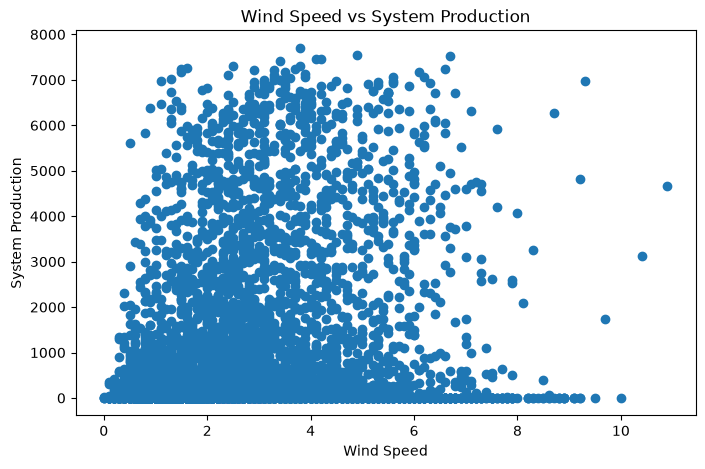

In [55]:
# Graph 5 : Wind Speed vs System Production

plt.figure(figsize = (8,5))
plt.scatter(
    df['WindSpeed'],
    df['SystemProduction']
)
plt.title('Wind Speed vs System Production')
plt.xlabel('Wind Speed')
plt.ylabel('System Production')
plt.show()

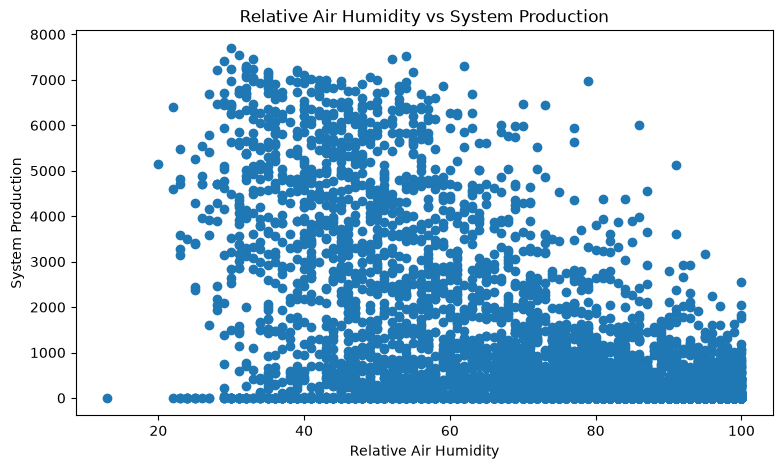

In [56]:
# Graph 6 : Relative Air Humidity vs System Production

plt.figure(figsize = (9,5))
plt.scatter(
    df['RelativeAirHumidity'],
    df['SystemProduction']
)
plt.title('Relative Air Humidity vs System Production')
plt.xlabel('Relative Air Humidity')
plt.ylabel('System Production')
plt.show()

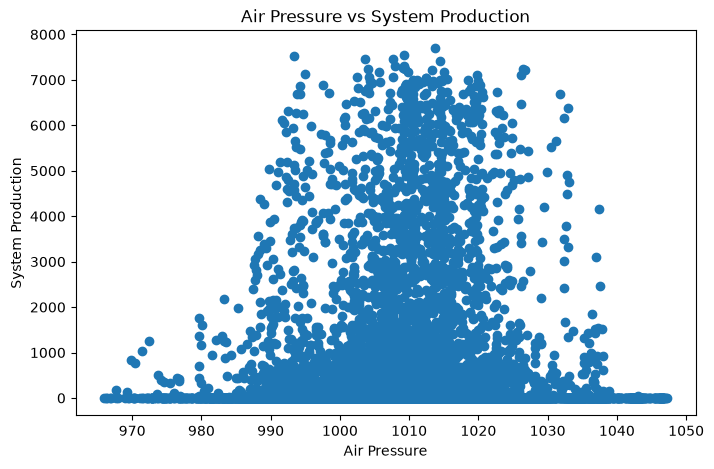

In [57]:
# Graph 7 : Air Pressure vs System Production

plt.figure(figsize = (8,5))
plt.scatter(
    df['AirPressure'],
    df['SystemProduction']
)
plt.title('Air Pressure vs System Production')
plt.xlabel('Air Pressure')
plt.ylabel('System Production')
plt.show()